# A CNN on PatchCamelyon (PCam)

**Task:** binary classification of 96×96 H&E patches from breast-cancer sentinel lymph nodes.
Label = 1 if the **central 32×32 region** contains at least one tumour pixel (metastasis), else 0.

| Split | Patches |
|---|---|
| train | 262,144 |
| valid | 32,768 |
| test | 32,768 |

**Before you start:** `Runtime → Change runtime type → T4 GPU`.

Notebook outline
1. Setup & download
2. Look at the data
3. Augmentation & data loaders
4. Build the CNN
5. Train (with validation AUC, checkpointing to Drive)
6. Evaluate on the test set
7. Inspect mistakes

## 1. Setup & Environment

**What this code does:** Installs required Python packages (`h5py`, `gdown`, etc.), imports necessary libraries (PyTorch, NumPy, Matplotlib), sets the random seeds for reproducibility, and configures the hardware device (GPU if available, otherwise CPU).

**Why we run it:** We need these libraries to process images, build neural networks, and evaluate metrics. Setting a fixed seed ensures that our experiments yield the same results if we run them multiple times.

In [1]:
!pip -q install h5py gdown scikit-learn

import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU - switch runtime!")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

Device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition


### Configuration

**What this code does:** Defines a central configuration dictionary (`CFG`) containing hyperparameters like batch size, learning rate, weight decay, and the number of training epochs.

**Why we run it:** Centralizing parameters makes it easy to track and tweak experiments without hunting through the entire notebook for hardcoded values. Increasing `train_fraction` and `weight_decay` here helped combat overfitting.

In [2]:
CFG = dict(
    train_fraction = 1.0,   # Increased to 1.0 (full dataset) to combat overfitting
    batch_size     = 256,
    epochs         = 10,
    lr             = 1e-3,
    weight_decay   = 1e-3,  # Increased regularization (was 1e-4)
    num_workers    = 2,
    patience       = 3,     # early stopping on validation AUC
)
DATA_DIR = "/content/pcam"   # Colab local disk (fast, wiped when session ends)

### Save checkpoints to Google Drive
The local disk is wiped when the session ends, so the best model is saved to Drive.

In [3]:
from google.colab import drive
drive.mount("/content/drive")
CKPT_DIR = "/content/drive/MyDrive/pcam_cnn"
os.makedirs(CKPT_DIR, exist_ok=True)

Mounted at /content/drive


### Download PCam (~7 GB compressed, takes a few minutes)
`torchvision.datasets.PCAM` downloads the official HDF5 files from Google Drive.
If it fails with a Google Drive quota error, wait a while and re-run (this is a known issue with popular files),
or see the TensorFlow Datasets alternative at the end of the notebook.

In [4]:
for split in ["train", "val", "test"]:
    datasets.PCAM(root=DATA_DIR, split=split, download=True)
!du -sh {DATA_DIR}

Downloading...
From (original): https://drive.google.com/uc?id=1Ka0XfEMiwgCYPdTI-vv6eUElOBnKFKQ2
From (redirected): https://drive.usercontent.google.com/download?id=1Ka0XfEMiwgCYPdTI-vv6eUElOBnKFKQ2&confirm=t&uuid=83bd5961-0b3e-4e77-a889-0f7c666ff2d8
To: /content/pcam/pcam/camelyonpatch_level_2_split_train_x.h5.gz
100%|██████████| 6.42G/6.42G [00:58<00:00, 109MB/s]
Downloading...
From: https://drive.google.com/uc?id=1269yhu3pZDP8UYFQs-NYs3FPwuK-nGSG
To: /content/pcam/pcam/camelyonpatch_level_2_split_train_y.h5.gz
100%|██████████| 21.4k/21.4k [00:00<00:00, 104MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1hgshYGWK8V-eGRy8LToWJJgDU_rXWVJ3
From (redirected): https://drive.usercontent.google.com/download?id=1hgshYGWK8V-eGRy8LToWJJgDU_rXWVJ3&confirm=t&uuid=43e404d5-d8c9-46e1-b6de-58d8ea374307
To: /content/pcam/pcam/camelyonpatch_level_2_split_valid_x.h5.gz
100%|██████████| 806M/806M [00:08<00:00, 100MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1bH8ZRbhSV

16G	/content/pcam


## 2. Exploratory Data Analysis (EDA)

**What this code does:** Loads the un-augmented training set and visualizes a 16-image random sample. It draws a green bounding box around the central 32x32 region, highlighting where the label (tumour vs normal) applies. The subsequent cell checks the dataset balance (ratio of positive to negative samples).

**Why we run it:** It's a fundamental best practice to visually inspect the data before modeling. Understanding that only the center region determines the label is critical for how we build the model. The class balance check ensures we don't have heavily skewed data.

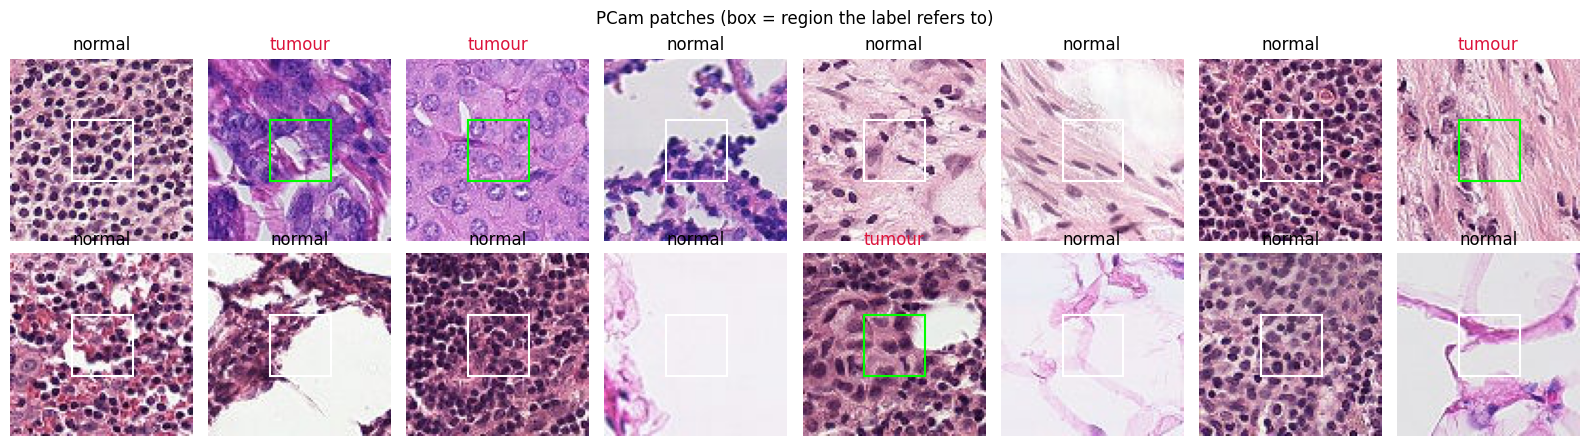

In [5]:
raw_train = datasets.PCAM(root=DATA_DIR, split="train")   # no transform -> PIL images

idx = np.random.choice(len(raw_train), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, idx):
    img, label = raw_train[i]
    ax.imshow(img)
    # the label refers to the central 32x32 square
    ax.add_patch(plt.Rectangle((32, 32), 32, 32, fill=False, ec="lime" if label else "white", lw=1.5))
    ax.set_title("tumour" if label else "normal", color="crimson" if label else "black")
    ax.axis("off")
plt.suptitle("PCam patches (box = region the label refers to)")
plt.tight_layout(); plt.show()

In [6]:
# Class balance (reading labels straight from the HDF5 file is much faster than iterating the dataset)
import h5py, glob
def load_labels(split):
    f = glob.glob(f"{DATA_DIR}/**/camelyonpatch_level_2_split_{split}_y.h5", recursive=True)[0]
    with h5py.File(f, "r") as h:
        return h["y"][:].reshape(-1)
for split in ["train", "valid", "test"]:
    y = load_labels(split)
    print(f"{split:5s}: n={len(y):6d}  tumour fraction = {y.mean():.3f}")

train: n=262144  tumour fraction = 0.500
valid: n= 32768  tumour fraction = 0.500
test : n= 32768  tumour fraction = 0.500


## 3. Data Augmentation & Loaders

**What this code does:** Defines image transformations (flips, 90-degree rotations, and minor color jitter) for the training set, and standard normalization for validation/test sets. It then wraps these in PyTorch `DataLoader` objects.

**Why we run it:** Histology patches have no natural "up" or "down", so rotating and flipping provides "free" artificial data, reducing overfitting (Data Augmentation). The `DataLoader` efficiently batches data and loads it in parallel using multiple CPU workers.

In [7]:
class RandomRot90:
    def __call__(self, x):
        return torch.rot90(x, k=random.randint(0, 3), dims=(1, 2))

MEAN, STD = [0.70, 0.54, 0.69], [0.18, 0.21, 0.16]   # approximate PCam statistics

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.04),
    transforms.ToTensor(),
    RandomRot90(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_ds = datasets.PCAM(root=DATA_DIR, split="train", transform=train_tf)
val_ds   = datasets.PCAM(root=DATA_DIR, split="val",   transform=eval_tf)
test_ds  = datasets.PCAM(root=DATA_DIR, split="test",  transform=eval_tf)

if CFG["train_fraction"] < 1.0:
    n = int(len(train_ds) * CFG["train_fraction"])
    train_ds = Subset(train_ds, np.random.choice(len(train_ds), n, replace=False))

loader_kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)
train_dl = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)
val_dl   = DataLoader(val_ds,   shuffle=False, **loader_kw)
test_dl  = DataLoader(test_ds,  shuffle=False, **loader_kw)
print(f"train {len(train_ds):,} | val {len(val_ds):,} | test {len(test_ds):,}")

train 262,144 | val 32,768 | test 32,768


## 4. Convolutional Neural Network (CNN) Architecture

**What this code does:** Defines a custom CNN (`SimpleCNN`) with four convolutional blocks (each containing Convolutions, BatchNorm, ReLU, and MaxPool layers). It ends with a Global Average Pooling layer and a fully connected classification head.

**Why we run it:** This architecture extracts visual features (edges, textures, cell shapes) from the 96x96 image patches and shrinks them down spatially while expanding the channel depth, ultimately collapsing the features into a single logit prediction for binary classification.

In [8]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, 1))

    def forward(self, x):
        return self.head(self.pool(self.features(x))).squeeze(1)   # shape: (batch,)

# Increased dropout to 0.5 to reduce overfitting
model = SimpleCNN(dropout=0.5).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params:,}")
with torch.no_grad():
    print("Output shape for a batch of 4:", model(torch.randn(4, 3, 96, 96, device=device)).shape)

Trainable parameters: 1,173,473
Output shape for a batch of 4: torch.Size([4])


In [9]:
!pip install -q torchinfo
from torchinfo import summary

# Visualize the model structure, output shapes, and parameters
summary(model, input_size=(CFG["batch_size"], 3, 96, 96),
        col_names=["input_size", "output_size", "num_params", "kernel_size"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
SimpleCNN                                [256, 3, 96, 96]          [256]                     --                        --
├─Sequential: 1-1                        [256, 3, 96, 96]          [256, 256, 6, 6]          --                        --
│    └─Sequential: 2-1                   [256, 3, 96, 96]          [256, 32, 48, 48]         --                        --
│    │    └─Conv2d: 3-1                  [256, 3, 96, 96]          [256, 32, 96, 96]         864                       [3, 3]
│    │    └─BatchNorm2d: 3-2             [256, 32, 96, 96]         [256, 32, 96, 96]         64                        --
│    │    └─ReLU: 3-3                    [256, 32, 96, 96]         [256, 32, 96, 96]         --                        --
│    │    └─Conv2d: 3-4                  [256, 32, 96, 96]         [256, 32, 96, 96]         9,216                     [3, 3]
│    │

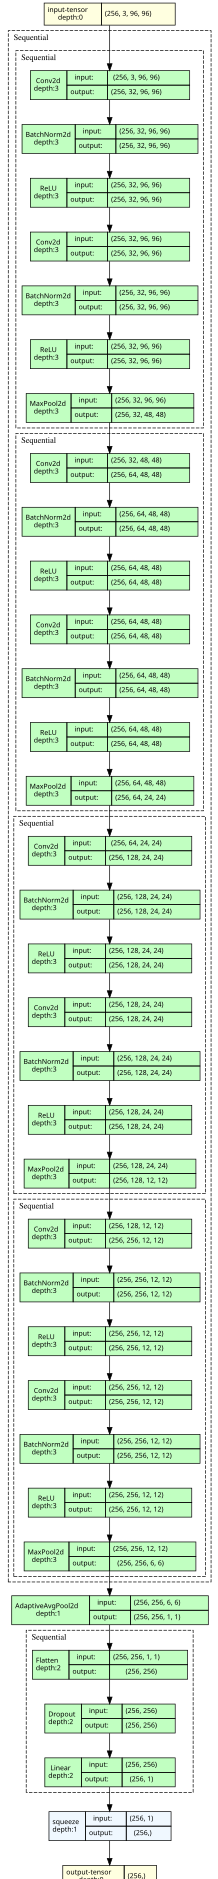

In [10]:
!pip install -q torchview graphviz
from torchview import draw_graph

# Generate a graphical node-based representation of the model structure
model_graph = draw_graph(model, input_size=(CFG["batch_size"], 3, 96, 96), device=device, expand_nested=True)
model_graph.visual_graph

## 5. Training Loop

**What this code does:** Initializes the loss function (`BCEWithLogitsLoss`), the optimizer (`AdamW`), a learning rate scheduler, and mixed-precision scaling. The training loop runs for `CFG["epochs"]`, doing a forward pass, backpropagation, and logging training loss and validation AUC.

**Why we run it:** This is the core learning phase. The optimizer updates the model's weights to minimize the loss. We use mixed precision (`autocast`) to speed up training on the GPU and save memory. Early stopping ensures we save the model that generalizes best to the validation set.

In [11]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"] * len(train_dl))
scaler = torch.amp.GradScaler(enabled=(device == "cuda"))

def train_one_epoch(model, loader):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.float().to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total_loss += loss.item() * len(y); n += len(y)
    return total_loss / n

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.float().to(device, non_blocking=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(x)
        losses.append(criterion(logits.float(), y).item() * len(y))
        probs.append(torch.sigmoid(logits.float()).cpu()); labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return probs, labels, sum(losses) / len(labels)

In [12]:
history = {"train_loss": [], "val_loss": [], "val_auc": [], "val_acc": []}
best_auc, bad_epochs = 0.0, 0
best_path = f"{CKPT_DIR}/simplecnn_best.pt"

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss = train_one_epoch(model, train_dl)
    p, y, va_loss = predict(model, val_dl)
    va_auc, va_acc = roc_auc_score(y, p), accuracy_score(y, p > 0.5)
    for k, v in zip(history, [tr_loss, va_loss, va_auc, va_acc]): history[k].append(v)

    flag = ""
    if va_auc > best_auc:
        best_auc, bad_epochs = va_auc, 0
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_auc": va_auc, "cfg": CFG}, best_path)
        flag = "  <- best, saved"
    else:
        bad_epochs += 1
    print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | "
          f"val AUC {va_auc:.4f} | val acc {va_acc:.4f} | {time.time()-t0:.0f}s{flag}")
    if bad_epochs >= CFG["patience"]:
        print(f"Early stopping: no improvement for {CFG['patience']} epochs."); break

epoch  1 | train loss 0.3252 | val loss 0.3226 | val AUC 0.9561 | val acc 0.8793 | 165s  <- best, saved
epoch  2 | train loss 0.2110 | val loss 0.4110 | val AUC 0.9189 | val acc 0.8562 | 164s
epoch  3 | train loss 0.1825 | val loss 0.3095 | val AUC 0.9529 | val acc 0.8806 | 165s
epoch  4 | train loss 0.1651 | val loss 0.2486 | val AUC 0.9674 | val acc 0.8992 | 163s  <- best, saved
epoch  5 | train loss 0.1518 | val loss 0.2905 | val AUC 0.9569 | val acc 0.8932 | 164s
epoch  6 | train loss 0.1386 | val loss 0.2826 | val AUC 0.9565 | val acc 0.8936 | 164s
epoch  7 | train loss 0.1280 | val loss 0.2544 | val AUC 0.9668 | val acc 0.9074 | 163s
Early stopping: no improvement for 3 epochs.


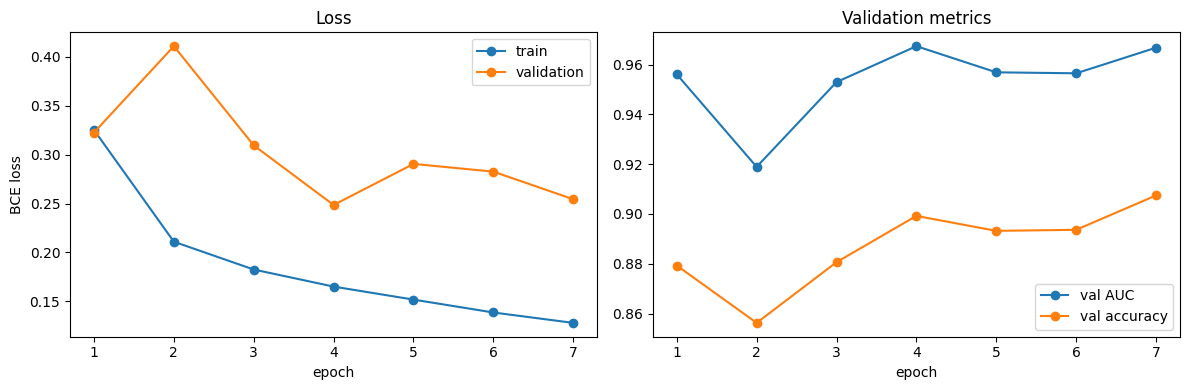

In [13]:
ep = range(1, len(history["train_loss"]) + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ep, history["train_loss"], "o-", label="train"); a1.plot(ep, history["val_loss"], "o-", label="validation")
a1.set_xlabel("epoch"); a1.set_ylabel("BCE loss"); a1.set_title("Loss"); a1.legend()
a2.plot(ep, history["val_auc"], "o-", label="val AUC"); a2.plot(ep, history["val_acc"], "o-", label="val accuracy")
a2.set_xlabel("epoch"); a2.set_title("Validation metrics"); a2.legend()
plt.tight_layout(); plt.show()

**Reading the curves:** if training loss keeps falling while validation loss rises, the model is overfitting
(more augmentation, more dropout, or more data helps). If both are still falling, train for more epochs.

## 6. Test-set Evaluation

**What this code does:** Restores the best saved weights (based on validation AUC) and runs predictions on the unseen test dataset. It calculates the final AUC, accuracy, sensitivity, and specificity, and plots the ROC curve and Confusion Matrix.

**Why we run it:** The validation set was used to tune early stopping, so evaluating on it is slightly biased. The test set provides our final, most rigorous estimation of how the model will perform on new, unseen data.

Loaded best model from epoch 4 (val AUC 0.9674)
Test AUC 0.9685 | accuracy 0.9034 | sensitivity 0.8702 | specificity 0.9366


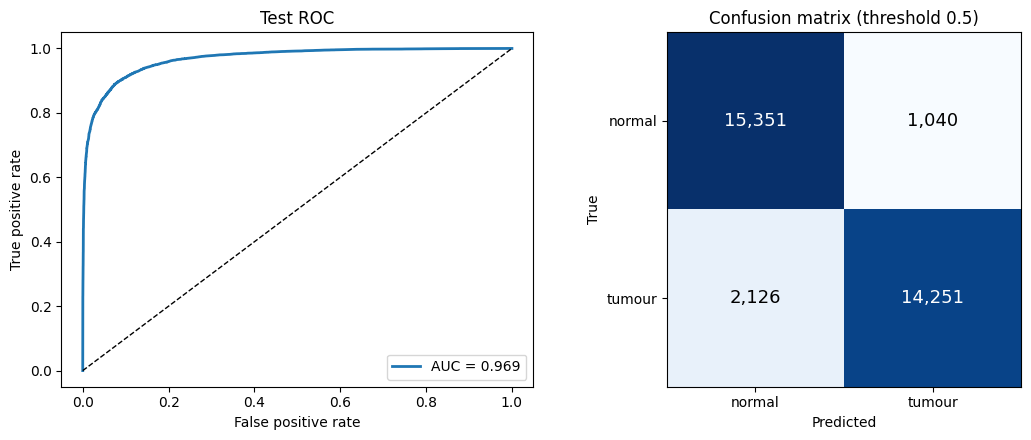

In [18]:
ckpt = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model"])
print(f"Loaded best model from epoch {ckpt['epoch']} (val AUC {ckpt['val_auc']:.4f})")

p_test, y_test, _ = predict(model, test_dl)
auc = roc_auc_score(y_test, p_test)
acc = accuracy_score(y_test, p_test > 0.5)
tn, fp, fn, tp = confusion_matrix(y_test, p_test > 0.5).ravel()
print(f"Test AUC {auc:.4f} | accuracy {acc:.4f} | sensitivity {tp/(tp+fn):.4f} | specificity {tn/(tn+fp):.4f}")

fpr, tpr, _ = roc_curve(y_test, p_test)
cm = np.array([[tn, fp], [fn, tp]])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
a1.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
a1.plot([0, 1], [0, 1], "k--", lw=1)
a1.set_xlabel("False positive rate")
a1.set_ylabel("True positive rate")
a1.set_title("Test ROC")
a1.legend()
a2.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    a2.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=13)
a2.set_xticks([0, 1], ["normal", "tumour"])
a2.set_yticks([0, 1], ["normal", "tumour"])
a2.set_xlabel("Predicted")
a2.set_ylabel("True")
a2.set_title("Confusion matrix (threshold 0.5)")
plt.tight_layout()
plt.show()

### Optional: test-time augmentation (TTA)
Average predictions over the 8 flips/rotations of each patch. Usually gives a small, free AUC gain.

In [17]:
@torch.no_grad()
def predict_tta(model, loader):
    model.eval(); probs = []
    for x, _ in loader:
        x = x.to(device); acc = 0
        for flip in [False, True]:
            xf = torch.flip(x, dims=[3]) if flip else x
            for k in range(4):
                with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                    acc = acc + torch.sigmoid(model(torch.rot90(xf, k, dims=(2, 3))).float())
        probs.append((acc / 8).cpu())
    return torch.cat(probs).numpy()

p_tta = predict_tta(model, test_dl)
print(f"Test AUC without TTA {auc:.4f} | with TTA {roc_auc_score(y_test, p_tta):.4f}")

Test AUC without TTA 0.9685 | with TTA 0.9700


## 7. Error Analysis (Look at the mistakes)

**What this code does:** Identifies the test set samples where the model was most confidently wrong (Top False Positives and Top False Negatives) and plots them.

**Why we run it:** Analyzing edge cases helps us understand what visual features confuse the model (e.g., artifacts, staining errors, or ambiguous tissues). This often inspires better data cleaning or specific augmentations.

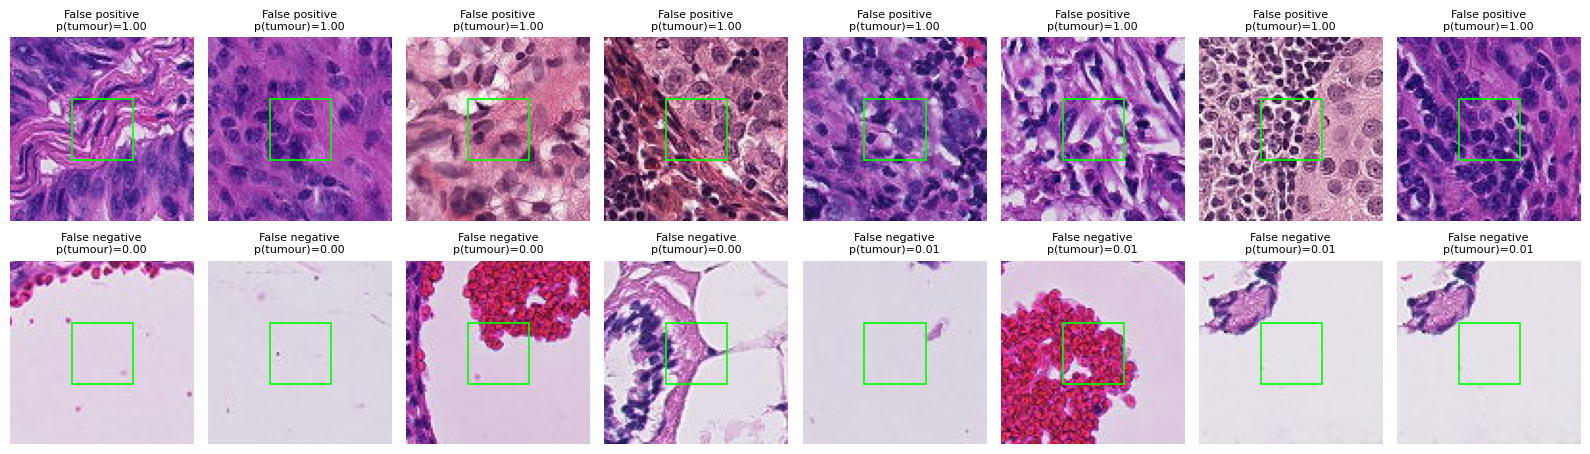

In [16]:
raw_test = datasets.PCAM(root=DATA_DIR, split="test")
pred = p_test > 0.5
fp_idx = np.where((pred == 1) & (y_test == 0))[0]
fn_idx = np.where((pred == 0) & (y_test == 1))[0]
# most confident mistakes
fp_idx = fp_idx[np.argsort(-p_test[fp_idx])][:8]
fn_idx = fn_idx[np.argsort(p_test[fn_idx])][:8]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for row, (ids, name) in enumerate([(fp_idx, "False positive"), (fn_idx, "False negative")]):
    for ax, i in zip(axes[row], ids):
        ax.imshow(raw_test[i][0]); ax.axis("off")
        ax.add_patch(plt.Rectangle((32, 32), 32, 32, fill=False, ec="lime", lw=1.2))
        ax.set_title(f"{name}\np(tumour)={p_test[i]:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

## Next steps
1. **Run the full dataset** (`train_fraction = 1.0`, ~15–20 epochs).
2. **Experiments to try one at a time**, comparing validation AUC: remove augmentation (how much does it matter?),
   change depth/width of the network, change the learning rate.
3. **Transfer learning:** replace `SimpleCNN` with `torchvision.models.resnet18(weights="IMAGENET1K_V1")`
   (change the last layer to `nn.Linear(512, 1)`) and compare. This is the bridge to the TCGA-BRCA pipeline,
   where a pretrained encoder extracts patch features.

---
### Alternative download (if Google Drive quota blocks torchvision)
```python
import tensorflow_datasets as tfds
ds = tfds.load("patch_camelyon", split="train", data_dir="/content/tfds")
```
This gives the same data as TF tensors; you would then need a small wrapper `Dataset` to use it with PyTorch.

## 8. Predict on a Custom Image
Upload your own 96x96 H&E patch to see what the model predicts.

Please upload an image file (e.g., .png, .jpg):


Saving tumour.png to tumour (1).png


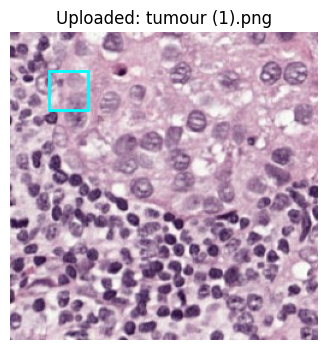


--- Prediction Results ---
Probability of Tumour: 0.1919
Diagnosis: NORMAL 🟩


In [23]:
from google.colab import files
from PIL import Image
import io

print("Please upload an image file (e.g., .png, .jpg):")
uploaded = files.upload()

if uploaded:
    # Get the first uploaded file
    filename = list(uploaded.keys())[0]
    img_data = uploaded[filename]

    # Open and convert image to RGB
    img = Image.open(io.BytesIO(img_data)).convert("RGB")

    # Display the uploaded image
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    # Draw the central 32x32 region
    plt.gca().add_patch(plt.Rectangle((32, 32), 32, 32, fill=False, ec="cyan", lw=2))
    plt.title(f"Uploaded: {filename}")
    plt.axis("off")
    plt.show()

    # Preprocess the image using the evaluation transforms
    # Resize to 96x96 just in case the uploaded image is of a different size
    img_resized = img.resize((96, 96))
    input_tensor = eval_tf(img_resized).unsqueeze(0).to(device)

    # Run the model
    model.eval()
    with torch.no_grad():
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            logit = model(input_tensor)
            prob = torch.sigmoid(logit.float()).item()

    print(f"\n--- Prediction Results ---")
    print(f"Probability of Tumour: {prob:.4f}")
    if prob > 0.5:
        print("Diagnosis: TUMOUR 🟥")
    else:
        print("Diagnosis: NORMAL 🟩")
else:
    print("No file was uploaded.")